# **Experiment 13: Summarization and Translation using T5/BART**

**Aim:**
To perform text summarization and machine translation using encoder-decoder Transformer models such as BART and T5.

**Brief Theory:**
T5 and BART are encoder-decoder Transformer architectures designed for sequence-to-sequence tasks. BART can generate concise summaries from long documents, while T5 can perform multiple text-to-text tasks, including translation. ROUGE and BLEU are automatic evaluation metrics used to compare generated text with reference text.

In [1]:
# Experiment 13
# Summarization and Translation using T5/BART

!pip install -q transformers sentencepiece sacrebleu rouge-score

import torch
import time
import pandas as pd
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

from rouge_score import rouge_scorer
from sacrebleu import corpus_bleu

print("Student Name: Abu Sayem")
print("Student ID: 25/SET/MTCE/014")
print("Libraries imported successfully!")
print("PyTorch Version:", torch.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Student Name: Abu Sayem
Student ID: 25/SET/MTCE/014
Libraries imported successfully!
PyTorch Version: 2.14.1+cpu


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Selected Device: cpu
Running on CPU


In [3]:
# Load BART Summarization Model
# use facebook/bart-large-cnn
summarization_model_name = "facebook/bart-large-cnn"

summary_tokenizer = AutoTokenizer.from_pretrained(
    summarization_model_name
)

summary_model = AutoModelForSeq2SeqLM.from_pretrained(
    summarization_model_name
).to(device)

summary_model.eval()

print("Summarization model loaded successfully!")
print("Model:", summarization_model_name)

config.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

Summarization model loaded successfully!
Model: facebook/bart-large-cnn


In [4]:
# Prepare two Sample Documents
documents = [
    """
    Artificial Intelligence is a rapidly growing field of computer science.
    It enables machines to perform tasks that normally require human intelligence.
    AI is widely used in healthcare, education, transportation and finance.
    Machine learning and deep learning are important technologies in AI.
    These technologies help computers learn from data, recognize patterns
    and make predictions. AI applications are improving productivity
    and supporting decision-making in many industries.
    """,

    """
    Climate change is one of the major environmental challenges in the world.
    Rising global temperatures cause melting glaciers, rising sea levels
    and extreme weather conditions. Human activities such as burning fossil
    fuels and deforestation contribute to global warming.
    Renewable energy sources, including solar and wind power,
    can help reduce greenhouse gas emissions.
    Governments and communities are working together to promote
    sustainable development and environmental protection.
    """
]

print("Total Documents:", len(documents))

for i, document in enumerate(documents, 1):
    print(f"\nDocument {i}:")
    print(document.strip())

Total Documents: 2

Document 1:
Artificial Intelligence is a rapidly growing field of computer science.
    It enables machines to perform tasks that normally require human intelligence.
    AI is widely used in healthcare, education, transportation and finance.
    Machine learning and deep learning are important technologies in AI.
    These technologies help computers learn from data, recognize patterns
    and make predictions. AI applications are improving productivity
    and supporting decision-making in many industries.

Document 2:
Climate change is one of the major environmental challenges in the world.
    Rising global temperatures cause melting glaciers, rising sea levels
    and extreme weather conditions. Human activities such as burning fossil
    fuels and deforestation contribute to global warming.
    Renewable energy sources, including solar and wind power,
    can help reduce greenhouse gas emissions.
    Governments and communities are working together to promote


In [5]:
# Generate Summaries Using BART
summaries = []
summary_times = []

for i, document in enumerate(documents, 1):

    inputs = summary_tokenizer(
        document,
        return_tensors="pt",
        max_length=512,
        truncation=True
    ).to(device)

    start_time = time.time()

    with torch.no_grad():
        outputs = summary_model.generate(
            **inputs,
            max_new_tokens=70,
            min_new_tokens=15,
            num_beams=4,
            early_stopping=True
        )

    elapsed_time = time.time() - start_time

    summary = summary_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    summaries.append(summary)
    summary_times.append(elapsed_time)

    print(f"\n========== SUMMARY {i} ==========")
    print("Original Document:")
    print(document.strip())

    print("\nGenerated Summary:")
    print(summary)

    print("Inference Time:", round(elapsed_time, 3), "seconds")

[transformers] Both `max_new_tokens` (=70) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=15) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



========== SUMMARY 1 ==========
Original Document:
Artificial Intelligence is a rapidly growing field of computer science.
    It enables machines to perform tasks that normally require human intelligence.
    AI is widely used in healthcare, education, transportation and finance.
    Machine learning and deep learning are important technologies in AI.
    These technologies help computers learn from data, recognize patterns
    and make predictions. AI applications are improving productivity
    and supporting decision-making in many industries.

Generated Summary:
Artificial Intelligence is a rapidly growing field of computer science. It enables machines to perform tasks that normally require human intelligence. Machine learning and deep learning are important technologies in AI.
Inference Time: 9.293 seconds


[transformers] Both `max_new_tokens` (=70) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=15) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



========== SUMMARY 2 ==========
Original Document:
Climate change is one of the major environmental challenges in the world.
    Rising global temperatures cause melting glaciers, rising sea levels
    and extreme weather conditions. Human activities such as burning fossil
    fuels and deforestation contribute to global warming.
    Renewable energy sources, including solar and wind power,
    can help reduce greenhouse gas emissions.
    Governments and communities are working together to promote
    sustainable development and environmental protection.

Generated Summary:
Climate change is one of the major environmental challenges in the world. Human activities such as burning fossil fuels and deforestation contribute to global warming. Renewable energy sources, including solar and wind power, can help reduce greenhouse gas emissions.
Inference Time: 10.754 seconds


In [7]:
# Prepare Reference Summaries
reference_summaries = [
    """Artificial Intelligence enables machines to perform
     intelligent tasks and is used in healthcare, education,
     transportation and finance.""",

    """Climate change causes rising temperatures, melting
     glaciers and extreme weather. Renewable energy and
     sustainable development can help reduce its effects."""
]

print("Reference summaries prepared successfully!")

Reference summaries prepared successfully!


In [8]:
# Calculate ROUGE Scores
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

rouge_results = []

for i in range(len(summaries)):

    scores = scorer.score(
        reference_summaries[i],
        summaries[i]
    )

    rouge_results.append({
        "Document": f"Document {i+1}",
        "ROUGE-1": scores["rouge1"].fmeasure,
        "ROUGE-2": scores["rouge2"].fmeasure,
        "ROUGE-L": scores["rougeL"].fmeasure
    })

rouge_df = pd.DataFrame(rouge_results)

print("========== ROUGE EVALUATION ==========")
print(rouge_df.round(4).to_string(index=False))

========== ROUGE EVALUATION ==========
  Document  ROUGE-1  ROUGE-2  ROUGE-L
Document 1   0.4583   0.1739   0.3750
Document 2   0.3051   0.1404   0.3051


In [9]:
# Load T5 Translation Model
translation_model_name = "t5-small"

translation_tokenizer = AutoTokenizer.from_pretrained(
    translation_model_name
)

translation_model = AutoModelForSeq2SeqLM.from_pretrained(
    translation_model_name
).to(device)

translation_model.eval()

print("Translation model loaded successfully!")
print("Model:", translation_model_name)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Translation model loaded successfully!
Model: t5-small


In [10]:
# Prepare Translation Dataset
source_sentences = [
    "Artificial Intelligence is changing the world.",
    "Machine Learning helps computers learn from data.",
    "Education is important for human development."
]

reference_translations = [
    "Künstliche Intelligenz verändert die Welt.",
    "Maschinelles Lernen hilft Computern, aus Daten zu lernen.",
    "Bildung ist wichtig für die menschliche Entwicklung."
]

print("Translation dataset prepared!")
print("Total sentences:", len(source_sentences))

Translation dataset prepared!
Total sentences: 3


In [11]:
# Generate Translations Using T5
translations = []
translation_times = []

for i, sentence in enumerate(source_sentences):

    prompt = "translate English to German: " + sentence

    inputs = translation_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    start_time = time.time()

    with torch.no_grad():
        outputs = translation_model.generate(
            **inputs,
            max_new_tokens=60,
            num_beams=4
        )

    elapsed_time = time.time() - start_time

    translated_text = translation_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    translations.append(translated_text)
    translation_times.append(elapsed_time)

    print(f"\n========== TRANSLATION {i+1} ==========")
    print("English:", sentence)
    print("German:", translated_text)
    print("Inference Time:", round(elapsed_time, 3), "seconds")


========== TRANSLATION 1 ==========
English: Artificial Intelligence is changing the world.
German: Die künstliche Intelligenz verändert die Welt.
Inference Time: 0.709 seconds

========== TRANSLATION 2 ==========
English: Machine Learning helps computers learn from data.
German: Machine Learning hilft Computern, aus Daten zu lernen.
Inference Time: 0.475 seconds

========== TRANSLATION 3 ==========
English: Education is important for human development.
German: Bildung ist wichtig für die menschliche Entwicklung.
Inference Time: 0.359 seconds


In [12]:
# Calculate BLEU Score
bleu_result = corpus_bleu(
    translations,
    [reference_translations]
)

print("========== BLEU EVALUATION ==========")
print("BLEU Score:", round(bleu_result.score, 2))

========== BLEU EVALUATION ==========
BLEU Score: 79.87


In [13]:
# Translation Comparison Table
translation_df = pd.DataFrame({
    "English Input": source_sentences,
    "Reference German": reference_translations,
    "Generated German": translations
})

print("========== TRANSLATION COMPARISON ==========")
print(translation_df.to_string(index=False))

========== TRANSLATION COMPARISON ==========
                                    English Input                                          Reference German                                       Generated German
   Artificial Intelligence is changing the world.                Künstliche Intelligenz verändert die Welt.         Die künstliche Intelligenz verändert die Welt.
Machine Learning helps computers learn from data. Maschinelles Lernen hilft Computern, aus Daten zu lernen. Machine Learning hilft Computern, aus Daten zu lernen.
    Education is important for human development.      Bildung ist wichtig für die menschliche Entwicklung.   Bildung ist wichtig für die menschliche Entwicklung.


In [14]:
# Summarization Performance Table
summary_df = pd.DataFrame({
    "Document": ["Document 1", "Document 2"],
    "Original Words": [
        len(doc.split()) for doc in documents
    ],
    "Summary Words": [
        len(summary.split()) for summary in summaries
    ],
    "Inference Time (sec)": [
        round(t, 3) for t in summary_times
    ]
})

print("========== SUMMARIZATION PERFORMANCE ==========")
print(summary_df.to_string(index=False))

========== SUMMARIZATION PERFORMANCE ==========
  Document  Original Words  Summary Words  Inference Time (sec)
Document 1              64             31                 9.293
Document 2              65             39                10.754


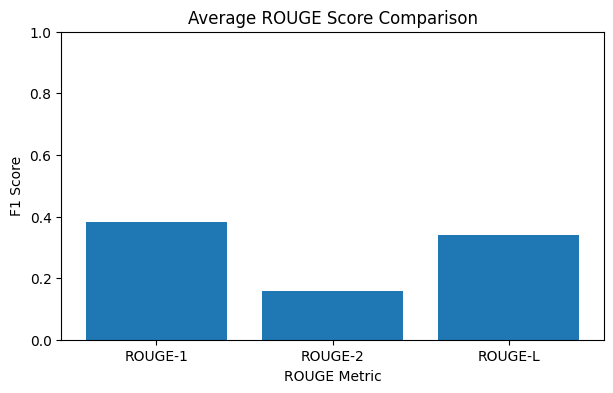

In [15]:
# Visualize ROUGE Scores
average_rouge = rouge_df[
    ["ROUGE-1", "ROUGE-2", "ROUGE-L"]
].mean()

plt.figure(figsize=(7, 4))

plt.bar(
    average_rouge.index,
    average_rouge.values
)

plt.title("Average ROUGE Score Comparison")
plt.xlabel("ROUGE Metric")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.show()

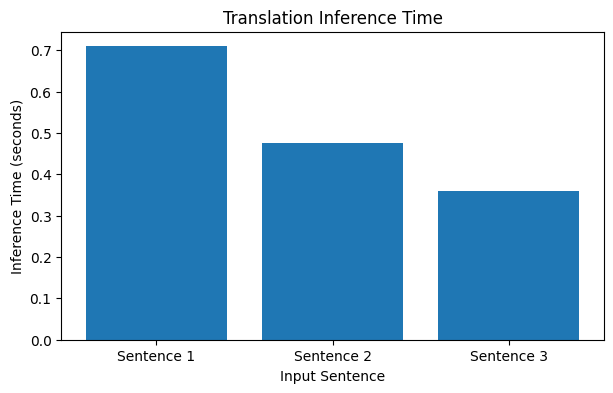

In [16]:
# Visualize Translation Inference Time
plt.figure(figsize=(7, 4))

plt.bar(
    ["Sentence 1", "Sentence 2", "Sentence 3"],
    translation_times
)

plt.title("Translation Inference Time")
plt.xlabel("Input Sentence")
plt.ylabel("Inference Time (seconds)")
plt.show()

In [18]:
# Final Experiment Summary
print("\n========== EXPERIMENT 13 SUMMARY ==========")

print("Student Name: Abu Sayem")
print("Student ID: 25/SET/MTCE/014")

print("\nSummarization:")
print("Model:", summarization_model_name)
print("Documents:", len(documents))
print("Average ROUGE-1:", round(average_rouge["ROUGE-1"], 4))
print("Average ROUGE-2:", round(average_rouge["ROUGE-2"], 4))
print("Average ROUGE-L:", round(average_rouge["ROUGE-L"], 4))

print("\nTranslation:")
print("Model:", translation_model_name)
print("Sentences:", len(source_sentences))
print("BLEU Score:", round(bleu_result.score, 2))

print("\nExperiment completed successfully!")


========== EXPERIMENT 13 SUMMARY ==========
Student Name: Abu Sayem
Student ID: 25/SET/MTCE/014

Summarization:
Model: facebook/bart-large-cnn
Documents: 2
Average ROUGE-1: 0.3817
Average ROUGE-2: 0.1571
Average ROUGE-L: 0.34

Translation:
Model: t5-small
Sentences: 3
BLEU Score: 79.87

Experiment completed successfully!


**Observation / Result**

**Observation:**

The experiment used BART for text summarization and T5 for English-to-German translation. Two sample documents were summarized, and three English sentences were translated into German. ROUGE metrics were used to evaluate summarization, while BLEU was used to evaluate translation quality against reference texts.

**Result:**

The experiment successfully demonstrated encoder-decoder Transformer models for summarization and translation. Generated summaries and translations were compared with reference texts using automatic evaluation metrics.
Interpretation
The experimental results demonstrate that encoder-decoder Transformer models can perform multiple sequence-to-sequence tasks. BART generated shorter versions of the original documents, while T5 generated translated sentences using task-specific instructions.

ROUGE scores measured the overlap between generated and reference summaries, whereas BLEU measured the overlap between generated and reference translations. Higher scores generally indicate better similarity to the reference texts.

However, automatic metrics cannot fully measure factual accuracy, meaning preservation, fluency or grammatical correctness. Therefore, manual inspection is also necessary.